# Overview
> **Chuyển đổi từ `5. Others/1_segnet.ipynb` sang PyTorch (Nạp dữ liệu thật từ `depth_hand.zip`)**
- Input: Ảnh độ sâu Kinect 96x96.
- Output: Mặt nạ phân đoạn 7 lớp bàn tay (`Palm`, `5 fingers`, `Background`) kèm ánh xạ màu `class_to_rgb`.


In [1]:
import time, zipfile
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
n_classes, img_h, img_w = 7, 96, 96


# (1) Data (Đọc thật từ `depth_hand.zip`)


SegNet Train: (120, 1, 96, 96) | Test: (40, 1, 96, 96)


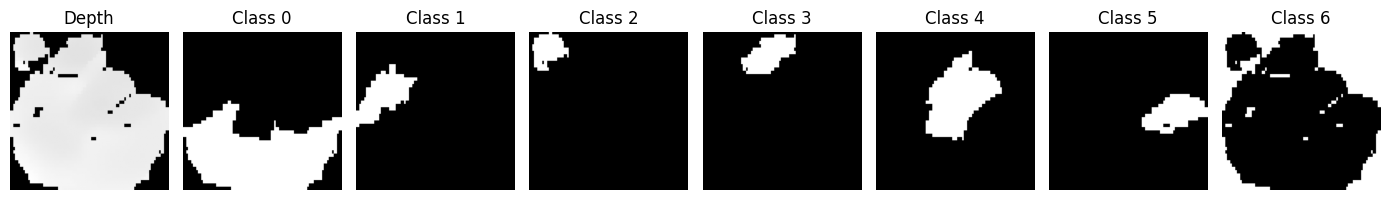

In [2]:
COLOR_TO_CLASS = {255: 0, 43: 1, 85: 2, 128: 3, 170: 4, 212: 5, 0: 6}
zip_path = Path('../../sample/examples/5. Others/depth_hand.zip')

def load_segnet_from_zip(zf, split, limit):
    prefix = f'data/segnet/{split}/depth/'
    files = sorted([n for n in zf.namelist() if n.startswith(prefix) and n.endswith('.png')])[:limit]
    xs, ys = [], []
    for d_fn in files:
        l_fn = d_fn.replace('depth', 'labels')
        with zf.open(d_fn) as fd, zf.open(l_fn) as fl:
            img = np.array(Image.open(fd).convert('L').resize((img_w, img_h), Image.NEAREST), dtype=np.float32)
            lbl = np.array(Image.open(fl).convert('L').resize((img_w, img_h), Image.NEAREST), dtype=np.uint8)
            cls_map = np.full((img_h, img_w), 6, dtype=np.int64)
            for gv, cid in COLOR_TO_CLASS.items():
                cls_map[lbl == gv] = cid
            xs.append(img); ys.append(cls_map)
    return np.array(xs)[:, None, :, :], np.array(ys)

with zipfile.ZipFile(zip_path, 'r') as zf:
    x_train, y_train = load_segnet_from_zip(zf, 'train', 120)
    x_test, y_test = load_segnet_from_zip(zf, 'test', 40)

train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=16, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test)), batch_size=16, shuffle=False)
print('SegNet Train:', x_train.shape, '| Test:', x_test.shape)

# Hiển thị 1 ảnh mẫu cùng 7 lớp mặt nạ nhị phân
plt.figure(figsize=(14, 2.5))
plt.subplot(1, 8, 1); plt.imshow(x_test[0, 0], cmap='gray'); plt.title('Depth'); plt.axis('off')
for c in range(7):
    plt.subplot(1, 8, c + 2); plt.imshow(y_test[0] == c, cmap='gray'); plt.title(f'Class {c}'); plt.axis('off')
plt.tight_layout(); plt.show()


# (2) Declare SegNet Encoder-Decoder Model


In [3]:
def conv_bn_relu(ic, oc):
    return nn.Sequential(nn.Conv2d(ic, oc, 3, padding=1), nn.BatchNorm2d(oc), nn.ReLU(inplace=True))

class SegNet(nn.Module):
    def __init__(self, in_c=1, n_cls=7):
        super().__init__()
        self.enc = nn.Sequential(
            conv_bn_relu(in_c, 64), conv_bn_relu(64, 64), nn.MaxPool2d(2, 2),
            conv_bn_relu(64, 128), conv_bn_relu(128, 128), nn.MaxPool2d(2, 2),
            conv_bn_relu(128, 256), conv_bn_relu(256, 256), conv_bn_relu(256, 256), nn.MaxPool2d(2, 2),
        )
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'), conv_bn_relu(256, 256), conv_bn_relu(256, 128),
            nn.Upsample(scale_factor=2, mode='nearest'), conv_bn_relu(128, 128), conv_bn_relu(128, 64),
            nn.Upsample(scale_factor=2, mode='nearest'), conv_bn_relu(64, 64),
            nn.Conv2d(64, n_cls, kernel_size=1), nn.BatchNorm2d(n_cls)
        )
    def forward(self, x):
        return self.dec(self.enc(x))

model = SegNet().to(device)
print('Params:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Params: 2881813


# (3) Train & (4) Evaluate + `class_to_rgb` Visualization


Epoch 01 | Test Loss: 1.6260 | Pixel Acc: 60.58%


Epoch 02 | Test Loss: 1.3717 | Pixel Acc: 66.29%


Epoch 03 | Test Loss: 1.2394 | Pixel Acc: 70.29%


Epoch 04 | Test Loss: 1.2010 | Pixel Acc: 69.70%


Epoch 05 | Test Loss: 1.1288 | Pixel Acc: 71.15%


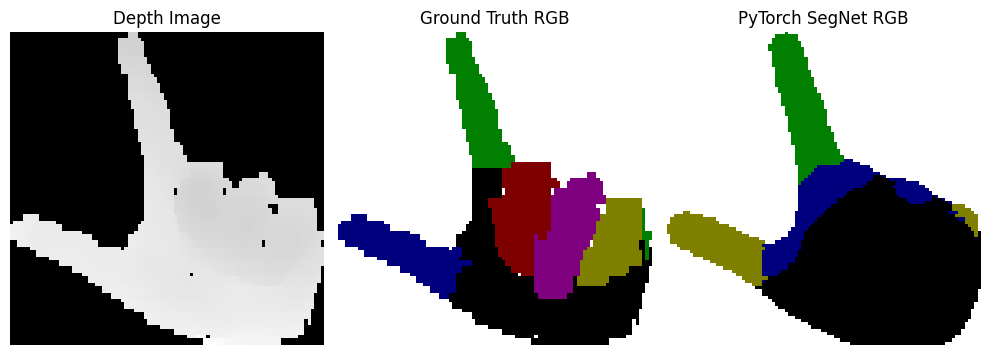

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
for ep in range(1, 6):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
    model.eval()
    te_loss, pix_acc = 0.0, 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            out = model(xb.to(device))
            te_loss += criterion(out, yb.to(device)).item() * len(xb)
            pix_acc += (out.argmax(1).cpu() == yb).float().mean().item() * len(xb)
    print(f'Epoch {ep:02d} | Test Loss: {te_loss/len(x_test):.4f} | Pixel Acc: {pix_acc/len(x_test)*100:.2f}%')

def class_to_rgb(mask):
    rgb = np.ones((img_h, img_w, 3), dtype=np.float32)
    palette = {0:[0,0,0], 1:[0,0,0.5], 2:[0,0.5,0], 3:[0.5,0,0], 4:[0.5,0,0.5], 5:[0.5,0.5,0], 6:[1,1,1]}
    for k, v in palette.items(): rgb[mask == k] = v
    return rgb

ran_ind = np.random.choice(len(x_test))
with torch.no_grad():
    pred_mask = model(torch.tensor(x_test[ran_ind:ran_ind+1]).to(device)).argmax(1).squeeze(0).cpu().numpy()

plt.figure(figsize=(10, 3.5))
plt.subplot(131); plt.imshow(x_test[ran_ind, 0], cmap='gray'); plt.title('Depth Image'); plt.axis('off')
plt.subplot(132); plt.imshow(class_to_rgb(y_test[ran_ind])); plt.title('Ground Truth RGB'); plt.axis('off')
plt.subplot(133); plt.imshow(class_to_rgb(pred_mask)); plt.title('PyTorch SegNet RGB'); plt.axis('off')
plt.tight_layout(); plt.show()
